# 02. Visit i overloaded

**Poziom: Praktyczne użycia**


## Spis treści

- [Problem](#sekcja-01)
- [Po tej części potrafisz](#sekcja-02)
- [Wykonanie](#sekcja-03)
- [1. `std::visit`: operacja dla aktywnej alternatywy](#sekcja-04)
    - [Demonstracja: Jedna operacja, różne typy](#sekcja-05)
- [2. `overloaded`: kilka lambd jako jeden odwiedzający](#sekcja-06)
    - [Demonstracja: Osobne lambdy i wspólny typ wyniku](#sekcja-07)
- [Artykuły i dokumentacja](#sekcja-08)
    - [Artykuły z przykładami](#sekcja-09)
    - [Dokumentacja konkretnych operacji](#sekcja-10)


<a id="sekcja-01"></a>

## Problem

Klient API ma ustawienia różnych typów, ale chcemy je wypisywać jedną wspólną operacją. Zamiast kolejnych instrukcji sprawdzających typ użyjemy `visit`, a potem połączymy osobne lambdy w `overloaded`.

<a id="sekcja-02"></a>

## Po tej części potrafisz

- Wyjaśnić, jak visit wybiera wywołanie dla przechowywanej wartości.
- Rozróżnić ogólną lambdę z if constexpr i osobne przeciążenia.
- Zapewnić poprawną obsługę wszystkich alternatyw oraz wspólny typ wyniku.

<a id="sekcja-03"></a>

## Wykonanie

Wybierz kernel Python 3 i wykonaj komórki od góry. Poniższa komórka Python przygotowuje `%%cpp`; każda komórka C++ zawiera własne nagłówki, definicje i `main()`. W razie problemu wróć do [sprawdzenia środowiska](00_start.ipynb).


In [1]:
import os
import shutil
import subprocess
from pathlib import Path
from tempfile import TemporaryDirectory

from IPython.core.magic import register_cell_magic

COMPILER_NAME = os.environ.get("CXX", "c++")

@register_cell_magic
def cpp(line: str, cell: str) -> None:
    """Kompiluje i uruchamia jedną niezależną demonstrację C++17."""
    option = line.strip()
    if option not in {"", "--expect-error"}:
        raise ValueError("Użyj %%cpp albo %%cpp --expect-error.")
    expect_error = option == "--expect-error"
    compiler = shutil.which(COMPILER_NAME)
    if compiler is None:
        raise RuntimeError(
            f"Nie znaleziono kompilatora {COMPILER_NAME!r}. "
            "Zainstaluj kompilator C++17 lub ustaw COMPILER_NAME."
        )
    with TemporaryDirectory(prefix="variant-notebook-") as directory:
        source = Path(directory) / "example.cpp"
        executable = Path(directory) / ("example.exe" if os.name == "nt" else "example")
        source.write_text(cell, encoding="utf-8")
        compiled = subprocess.run(
            [compiler, "-std=c++17", "-Wall", "-Wextra", "-Wpedantic", "-Werror",
             str(source), "-o", str(executable)],
            capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=60,
        )
        if expect_error:
            if compiled.returncode == 0:
                raise RuntimeError("Oczekiwano błędu kompilacji, ale program skompilował się poprawnie.")
            print("Oczekiwany błąd kompilacji. Początek komunikatu kompilatora:")
            diagnostics = (compiled.stdout + compiled.stderr).replace(str(source), "example.cpp").splitlines()
            print("\n".join(diagnostics[:16]))
            if len(diagnostics) > 16:
                print("[Dalsza część komunikatu została pominięta.]")
            return
        if compiled.returncode != 0:
            raise RuntimeError("Błąd kompilacji:\n" + compiled.stdout + compiled.stderr)
        executed = subprocess.run(
            [str(executable)], capture_output=True, text=True,
            encoding="utf-8", errors="replace", timeout=10,
        )
        print(executed.stdout, end="")
        if executed.stderr:
            print(executed.stderr, end="")
        if executed.returncode != 0:
            raise RuntimeError(f"Program zakończył się kodem {executed.returncode}.")

print(f"Gotowe: %%cpp używa {COMPILER_NAME}, standard C++17.")

Gotowe: %%cpp używa c++, standard C++17.


<a id="sekcja-04"></a>

## 1. `std::visit`: operacja dla aktywnej alternatywy

Seria `if (holds_alternative<...>)` szybko się rozrasta. `std::visit(f, v)` wywołuje `f` z aktualnie przechowywaną wartością. Sama funkcja nie musi ręcznie sprawdzać indeksu.


In [2]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> v{12};
    std::visit(
        [](const auto& x) {
            std::cout << x;
        },
        v
    );

    std::cout << '\n';
}


12


`[]` zaczyna lambdę - niewielki obiekt zachowujący się jak funkcja. Puste nawiasy oznaczają brak przechwytywania zmiennych z otoczenia. Parametr `const auto&` oznacza referencję bez kopiowania i modyfikacji; `auto` sprawia, że operator wywołania lambdy jest szablonem dopasowywanym do typu argumentu.

Odwiedzający musi dać się wywołać dla **każdej alternatywy**, a nie tylko tej aktywnej przy konkretnym uruchomieniu. Dla powyższego kodu każdy możliwy typ musi obsługiwać wypisywanie przez `<<`.

Następna komórka odróżnia tekst od liczby wewnątrz lambdy `describe`. Wywołuje ją raz dla liczby 12, a raz dla tekstu `kot`:


In [3]:
%%cpp
#include <iostream>
#include <string>
#include <variant>
#include <type_traits>

int main() {
    const auto describe = [](const auto& item) {
        using T = std::decay_t<decltype(item)>;
        if constexpr (std::is_same_v<T, std::string>) {
            std::cout << item.size();
        } else {
            std::cout << item + 1;
        }
        std::cout << '\n';
    };
    describe(12);
    describe(std::string{"kot"});
}


13
3


`decltype(item)` odczytuje typ parametru, np. `const std::string&`. Dla użytych typów `std::decay_t` usuwa referencję i kwalifikator `const`. `std::is_same_v` porównuje typy. `if constexpr` wybiera gałąź podczas instancjowania szablonu: gałąź z `.size()` nie musi być poprawna dla `int`. Zwykłe `if` nie daje tego efektu. W odrzucanej gałęzi nadal musi być poprawna składnia; nie jest to sposób ukrywania dowolnego błędu.


<a id="sekcja-05"></a>

### Demonstracja: Jedna operacja, różne typy

Komórka pokazuje wypisywanie obu typów oraz wybór działania przez `if constexpr`.


In [4]:
%%cpp
// Cel: jedna operacja dla każdej alternatywy oraz rozgałęzienie w kompilacji.
#include <iostream>
#include <string>
#include <type_traits>
#include <variant>

int main() {
    std::variant<int, std::string> value{12};
    const auto print = [](const auto& item) {
        std::cout << "wartosc: " << item << '\n';
    };
    const auto describe = [](const auto& item) {
        using T = std::decay_t<decltype(item)>;
        if constexpr (std::is_same_v<T, std::string>) {
            std::cout << "dlugosc: " << item.size() << '\n';
        } else {
            std::cout << "liczba + 1: " << item + 1 << '\n';
        }
    };
    std::visit(print, value);
    std::visit(describe, value);
    value = std::string{"kot"};
    std::visit(print, value);
    std::visit(describe, value);
}


wartosc: 12
liczba + 1: 13
wartosc: kot
dlugosc: 3


**Jak czytać wynik:** Dla liczby wykonywane jest dodawanie, a dla tekstu obliczenie długości. `if constexpr` pozwala pominąć niepasującą gałąź podczas tworzenia konkretnej instancji lambdy.


<a id="sekcja-06"></a>

## 2. `overloaded`: kilka lambd jako jeden odwiedzający

Czasem czytelniej napisać oddzielną funkcję dla każdego typu. W C++17 można połączyć lambdy tak:


In [5]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

template <class... Ts>
struct overloaded : Ts... {
    using Ts::operator()...;
};
template <class... Ts>
overloaded(Ts...) -> overloaded<Ts...>;

int main() {
    const auto print = overloaded{
        [](int x) {
            std::cout << "liczba: " << x << '\n';
        },
        [](const std::string& x) {
            std::cout << "tekst: " << x << '\n';
        }
    };
    print(42);
    print(std::string{"kot"});
}


liczba: 42
tekst: kot


`Ts...` to lista typów. Struktura dziedziczy po obiektach funkcyjnych, a `using` udostępnia wszystkie ich operatory wywołania. Deklaracja `overloaded(Ts...) -> overloaded<Ts...>` jest wskazówką dedukcji: pozwala kompilatorowi wywnioskować typy lambd z argumentów. Jest potrzebna w tym zapisie dla C++17. To **nasz pomocniczy szablon**, nie część biblioteki standardowej.


In [6]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

template <class... Ts>
struct overloaded : Ts... {
    using Ts::operator()...;
};
template <class... Ts>
overloaded(Ts...) -> overloaded<Ts...>;

int main() {
    std::variant<int, std::string> v{std::string{"kot"}};
    std::visit(
        overloaded{
            [](int x) {
                std::cout << "liczba: " << x;
            },
            [](const std::string& x) {
                std::cout << "tekst: " << x;
            }
        },
        v
    );

    std::cout << '\n';
}


tekst: kot


Demonstracja poniżej rozszerza obsługę o `double`, a następnie pokazuje odwiedzającego, który zamienia każdą wartość na `std::string`.

W C++17 wszystkie możliwe wywołania w jednym `std::visit` muszą mieć ten sam typ wyniku i tę samą kategorię wartości. `int` w jednym przypadku i `double` w drugim nie wystarczą, nawet jeśli jedno konwertuje się do drugiego. W poniższej demonstracji jawne `-> std::string` zapewnia wspólny wynik. Przy wypisywaniu wszystkie gałęzie zwracają `void`.

Pułapka: przeciążenia dopuszczają konwersje. Jeśli usuniesz obsługę `int`, funkcja przyjmująca `double` może nadal go przyjąć. Ogólna lambda `auto` również może obsłużyć nowo dodany typ. Kompilator sprawdza poprawność wywołania, a nie to, czy świadomie zaprojektowałeś obsługę każdego przypadku.

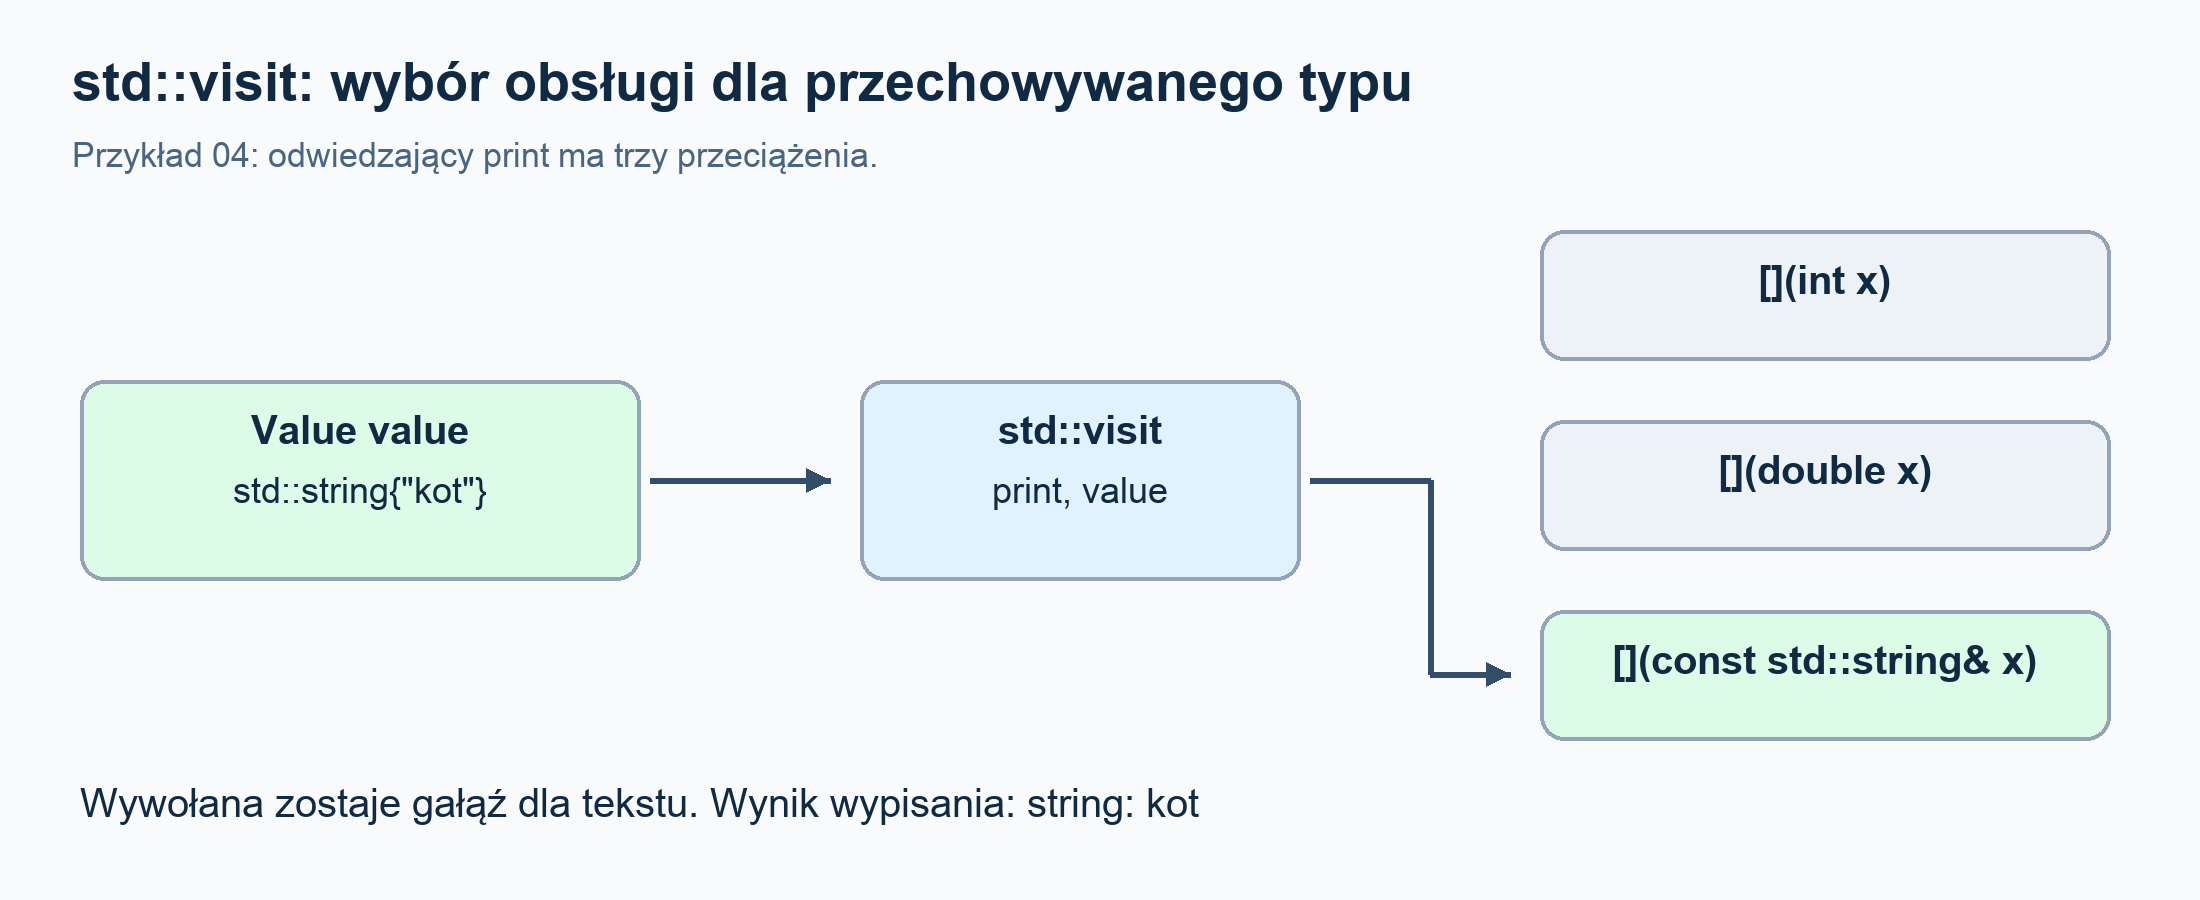

Wszystkie trzy gałęzie odwiedzającego muszą być poprawne, choć pojedyncze wywołanie `visit` wybiera jedną z nich.


<a id="sekcja-07"></a>

### Demonstracja: Osobne lambdy i wspólny typ wyniku

Pierwszy odwiedzający wypisuje wartości, a drugi buduje ich tekstowe opisy i pozwala odczytać długości tych opisów.


In [7]:
%%cpp
// Cel: osobne przeciążenia i jawny wspólny typ wyniku odwiedzającego.
#include <iostream>
#include <sstream>
#include <string>
#include <variant>

template <class... Ts>
struct overloaded : Ts... {
    using Ts::operator()...;
};
template <class... Ts>
overloaded(Ts...) -> overloaded<Ts...>;

int main() {
    using Value = std::variant<int, double, std::string>;
    const auto print = overloaded{
        [](int x) {
            std::cout << "int: " << x << '\n';
        },
        [](double x) {
            std::cout << "double: " << x << '\n';
        },
        [](const std::string& x) {
            std::cout << "string: " << x << '\n';
        }
    };
    const auto as_text = [](const auto& x) -> std::string {
        std::ostringstream out;
        out << x;
        return out.str();
    };
    const Value values[] = {Value{4}, Value{2.5}, Value{std::string{"kot"}}};
    for (const auto& value : values) {
        std::visit(print, value);
    }
    std::cout << "dlugosci opisow:";
    for (const auto& value : values) {
        std::cout << ' ' << std::visit(as_text, value).size();
    }
    std::cout << '\n';
}


int: 4
double: 2.5
string: kot
dlugosci opisow: 1 3 3


**Jak czytać wynik:** Wypisywanie wybiera jedno z trzech przeciążeń. Drugi odwiedzający zwraca zawsze `std::string`, dlatego można następnie odczytać długość każdego opisu.


<a id="sekcja-08"></a>

## Artykuły i dokumentacja

<a id="sekcja-09"></a>

### Artykuły z przykładami

- [C++ Stories: The overload Pattern](https://www.cppstories.com/2019/02/2lines3featuresoverload.html/) - wyjaśnienie łączenia lambd krok po kroku.
- [C++ Stories: Everything You Need to Know About std::variant](https://www.cppstories.com/2018/06/variant/) - wprowadzenie i praktyczne zastosowania.

<a id="sekcja-10"></a>

### Dokumentacja konkretnych operacji

- [cppreference: std::visit (funkcja wolna, od C++17)](https://en.cppreference.com/cpp/utility/variant/visit2) - wywoływanie odwiedzającego dla jednego lub wielu wariantów.
- [cppreference: std::variant](https://en.cppreference.com/cpp/utility/variant) - operacje i wymagania wariantu.

W artykułach i dokumentacji występują także rozszerzenia późniejszych standardów. Przykłady tego rozdziału pozostają w C++17.


[Poprzednia część](01_podstawy.ipynb) | [Start](00_start.ipynb) | [Pełny przewodnik](../PRZEWODNIK.md) | [Następny rozdział](03_zastosowania.ipynb)
